In [1]:
import pandas as pd

df = pd.read_csv("../data/student-mat.csv", sep=";")
print(df.shape)                       
df["at_risk"] = (df["G3"] < 10).astype(int)
print(df["at_risk"].value_counts(normalize=True))
df.head()

(395, 33)
at_risk
0    0.670886
1    0.329114
Name: proportion, dtype: float64


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,at_risk
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,0


In [2]:
print(df.isnull().sum().sum())   # total missing values
df.dtypes.value_counts()         # how many numeric vs text columns

0


str      17
int64    17
Name: count, dtype: int64

In [4]:
print(df.groupby("failures")["at_risk"].agg(["mean", "count"]))
print(df.groupby("studytime")["at_risk"].agg(["mean", "count"]))

              mean  count
failures                 
0         0.250000    312
1         0.520000     50
2         0.823529     17
3         0.750000     16
               mean  count
studytime                 
1          0.352381    105
2          0.353535    198
3          0.246154     65
4          0.259259     27


In [5]:
drop_cols = ["G1", "G2", "G3", "at_risk",
             "sex", "age", "address", "famsize", "Pstatus",
             "Medu", "Fedu", "Mjob", "Fjob", "guardian", "reason",
             "romantic", "Dalc", "Walc"]

X = df.drop(columns=drop_cols)
y = df["at_risk"]

print("df:", df.shape)
print("X:", X.shape)
print(list(X.columns))

df: (395, 34)
X: (395, 16)
['school', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'famrel', 'freetime', 'goout', 'health', 'absences']


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X, y, df, test_size=0.2, stratify=y, random_state=42
)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
], verbose_feature_names_out=False)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("At-risk share in train:", round(y_train.mean(), 3))
print("At-risk share in test:", round(y_test.mean(), 3))
print("Numeric:", num_cols)
print("Text:", cat_cols)

Train: (316, 16) Test: (79, 16)
At-risk share in train: 0.329
At-risk share in test: 0.329
Numeric: ['traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'health', 'absences']
Text: ['school', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet']


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

pipe.fit(X_train, y_train)

pred = pipe.predict(X_test)
proba = pipe.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred, target_names=["Not at risk", "At risk"]))

ROC-AUC: 0.71
              precision    recall  f1-score   support

 Not at risk       0.77      0.68      0.72        53
     At risk       0.47      0.58      0.52        26

    accuracy                           0.65        79
   macro avg       0.62      0.63      0.62        79
weighted avg       0.67      0.65      0.65        79



In [9]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

# precision and recall at different thresholds
for t in [0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    print(f"threshold {t}: precision {precision_score(y_test, p):.2f}, "
          f"recall {recall_score(y_test, p):.2f}, flagged {p.sum()}")

# actual at-risk rate inside each band
bands = pd.cut(proba, bins=[0, 0.4, 0.6, 1.0], labels=["Low", "Medium", "High"])
check = pd.DataFrame({"band": bands, "actual": y_test.values})
print(check.groupby("band", observed=True)["actual"].agg(["mean", "count"]))

threshold 0.4: precision 0.45, recall 0.88, flagged 51
threshold 0.5: precision 0.47, recall 0.58, flagged 32
threshold 0.6: precision 0.50, recall 0.38, flagged 20
threshold 0.7: precision 0.69, recall 0.35, flagged 13
            mean  count
band                   
Low     0.107143     28
Medium  0.419355     31
High    0.500000     20


In [10]:
bands = pd.cut(proba, bins=[0, 0.4, 0.7, 1.0], labels=["Low", "Medium", "High"], right=False)
check = pd.DataFrame({"band": bands, "actual": y_test.values})
print(check.groupby("band", observed=True)["actual"].agg(["mean", "count"]))

            mean  count
band                   
Low     0.107143     28
Medium  0.368421     38
High    0.692308     13


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(5, shuffle=True, random_state=42)

rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=6,
                                   class_weight="balanced", random_state=42)),
])

for name, p in [("Logistic regression", pipe), ("Random forest", rf_pipe)]:
    scores = cross_val_score(p, X_train, y_train, cv=cv, scoring="roc_auc")
    print(name, "CV AUC:", round(scores.mean(), 3), "+/-", round(scores.std(), 3))

Logistic regression CV AUC: 0.636 +/- 0.053
Random forest CV AUC: 0.674 +/- 0.091


c:\Users\PMLS\Desktop\explain-my-learning-risk\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Matplotlib is building the font cache; this may take a moment.
Background dataset has 316 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=316 when initializing the masker.


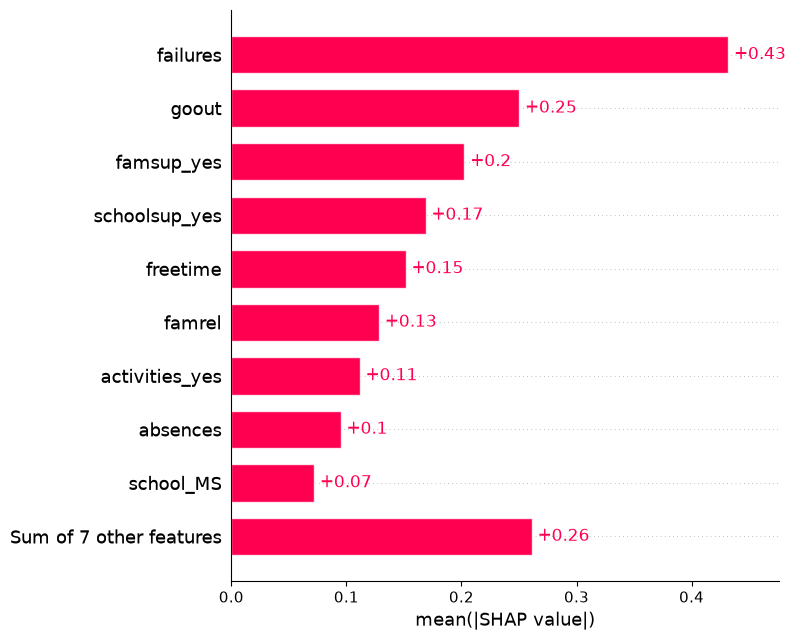

In [12]:
import shap
import matplotlib.pyplot as plt

prep = pipe.named_steps["prep"]
clf = pipe.named_steps["clf"]
feature_names = prep.get_feature_names_out()

Xtr = pd.DataFrame(prep.transform(X_train), columns=feature_names)
Xte = pd.DataFrame(prep.transform(X_test), columns=feature_names)

explainer = shap.Explainer(clf, Xtr)
shap_test = explainer(Xte)

shap.plots.bar(shap_test, max_display=10, show=False)
plt.tight_layout()
plt.savefig("../global_shap.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
coef = pd.Series(clf.coef_[0], index=feature_names).sort_values()
print(coef.round(2))

higher_yes       -0.65
internet_yes     -0.24
freetime         -0.21
famrel           -0.19
studytime         0.01
paid_yes          0.01
traveltime        0.03
health            0.08
absences          0.14
nursery_yes       0.16
activities_yes    0.22
school_MS         0.34
goout             0.37
famsup_yes        0.42
schoolsup_yes     0.61
failures          0.66
dtype: float64


Risk estimate: 0.93 | Actually at risk: True
school         GP
traveltime      1
studytime       2
failures        3
schoolsup      no
famsup        yes
paid           no
activities     no
nursery        no
higher         no
internet       no
famrel          3
freetime        4
goout           2
health          5
absences        2
Name: 127, dtype: object


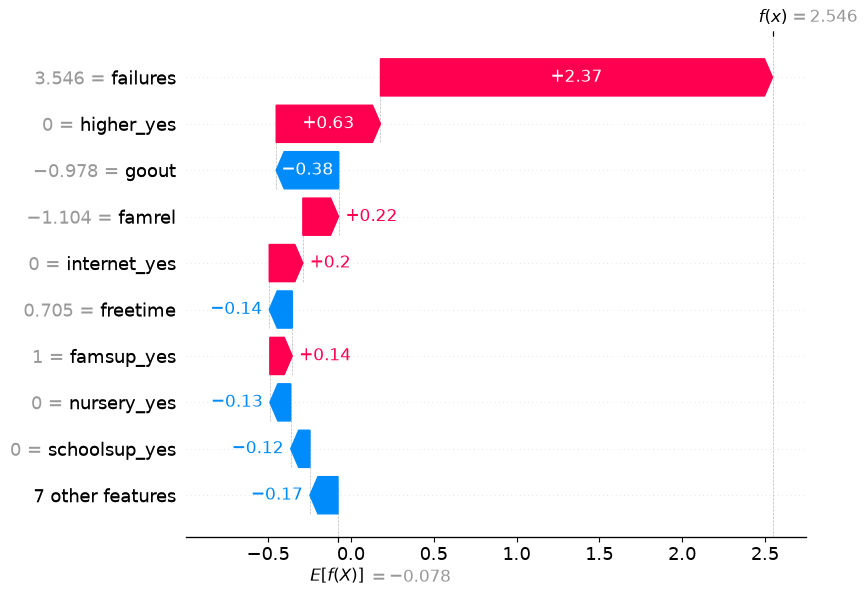

In [14]:
import numpy as np

i = int(np.argmax(proba))   # the highest-risk student in the test set

print("Risk estimate:", round(proba[i], 2), "| Actually at risk:", bool(y_test.iloc[i]))
print(X_test.iloc[i])

shap.plots.waterfall(shap_test[i], max_display=10)

In [16]:
YESNO = {
    "higher":     ("Planning to pursue higher education", "Not planning to pursue higher education"),
    "internet":   ("Having internet access at home", "Having no internet access at home"),
    "famsup":     ("Receiving family educational support", "Not receiving family educational support"),
    "schoolsup":  ("Receiving extra school support", "Not receiving extra school support"),
    "nursery":    ("Having attended nursery school", "Not having attended nursery school"),
    "activities": ("Taking part in extracurricular activities", "Not taking part in extracurricular activities"),
    "paid":       ("Taking paid extra classes", "Not taking paid extra classes"),
}
SCALE = {
    "goout": "going out with friends", "famrel": "family relationship quality",
    "freetime": "free time after school", "health": "health status",
    "studytime": "weekly study time", "traveltime": "travel time to school",
}
SUPPORT = {"schoolsup", "famsup"}
median = X_train.median(numeric_only=True)

def to_raw_col(name):
    for c in X.columns:
        if name == c or name.startswith(c + "_"):
            return c

def describe(col, val):
    if col in YESNO:
        return YESNO[col][0] if val == "yes" else YESNO[col][1]
    if col == "failures":
        return f"Having {val} past class failure{'s' if val != 1 else ''}"
    if col == "absences":
        return f"Having {val} school absence{'s' if val != 1 else ''}"
    if col == "school":
        return "The school attended"
    if val == median[col]:
        return f"A typical level of {SCALE[col]}"
    direction = "higher" if val > median[col] else "lower"
    return f"A {direction}-than-typical level of {SCALE[col]} ({val} on a 1-5 scale)"

def explain_in_words(i, top_k=3):
    sv = pd.Series(shap_test[i].values, index=feature_names)
    raw = X_test.iloc[i]
    lines = []
    for name in sv[sv > 0].sort_values(ascending=False).head(top_k).index:
        col = to_raw_col(name)
        d = describe(col, raw[col])
        if col in SUPPORT:
            lines.append(f"RAISES: {d} appears alongside higher risk in this data, "
                         "probably because support goes to students who already need it.")
        else:
            lines.append(f"RAISES: {d} is increasing the model's risk estimate.")
    for name in sv[sv < 0].sort_values().head(2).index:
        col = to_raw_col(name)
        lines.append(f"LOWERS: {describe(col, raw[col])} is lowering the model's risk estimate.")
    return lines

print("Risk estimate:", round(proba[i], 2))
for line in explain_in_words(i):
    print(line)

Risk estimate: 0.93
RAISES: Having 3 past class failures is increasing the model's risk estimate.
RAISES: Not planning to pursue higher education is increasing the model's risk estimate.
RAISES: A lower-than-typical level of family relationship quality (3 on a 1-5 scale) is increasing the model's risk estimate.
LOWERS: A lower-than-typical level of going out with friends (2 on a 1-5 scale) is lowering the model's risk estimate.
LOWERS: A higher-than-typical level of free time after school (4 on a 1-5 scale) is lowering the model's risk estimate.


In [17]:
import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump({
    "pipe": pipe,
    "columns": list(X.columns),
    "feature_names": list(feature_names),
    "X_bg": Xtr.sample(100, random_state=0),
    "median": X_train.median(numeric_only=True),
    "thresholds": (0.4, 0.7),
}, "../models/risk_model.joblib")
print("saved")

saved
